In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import LinearSegmentedColormap

In [4]:
#taking 2 moons and finding is it blue-0 or orange-1
def moons (n,r,noise=0.25):
  t,lab=r.uniform(0,np.pi,n),r.integers(0,2,n)
  top=np.c_[np.cos(t),np.sin(t)]
  bottom= np.c_[1-np.cos(t),0.5 -np.sin(t)]
  x=np.where(lab[:,None]==0,top,bottom)
  return x+r.normal(0,noise,(n,2)),lab

rng= np.random.default_rng(0)
X,Y=moons(1000,rng)                         #training data
Xt,Yt=moons(1000,np.random.default_rng(1))  #useen test data

In [14]:
H=16        #nurons per layer
shapes={"W1":(2,H),"b1":(H,),"W2":(H,H),"b2":(H,),"W3":(H,1),"b3":(1,)}
p={k:rng.normal(0,.5,sh) if k[0]=="W" else np.zeros(sh)
      for k,sh in shapes.items()}
m={k:0*v for k, v in p.items()}
s={k: 0*v for k,v in p.items()}

In [6]:
relu= lambda z:np.maximum(z,0)
sigmoid = lambda z: 1/(1+np.exp(-z))
def forward(x):
  z1=x @ p["W1"]+p["b1"];h1=relu(z1)          #layer 1
  z2=h1 @ p["W2"]+p["b2"];h1=relu(z2)         #layer 2
  out = sigmoid(h2 @ p["W3"]+p["b3"]).ravel()#P orange
  return out, (z1,h1,z2,h2)

In [11]:
def step(it,lr=1e-2):
  i=rng.integers(0,len(X),256)
  x,y=X[i],Y[i]
  out,(z1,h1,z2,h2)=forward(x)
  d3=(out-y)[:,None]/len(y)
  g={"W3":h2.T @ d3,"b3":d3.sum(0)}
  d2=(d3 @ p["W3"].T)*(z2>0)
  g["W2"],g["b2"]=h1.T @ d2,d2.sum(0)
  d1=(d2 @ p["W2"].T)*(z1>0)
  g["W1"],g["b1"]=x.T @ d1,d1.sum(0)
  for k in p:
    # Normalizing keys from 'w1' to 'W1' if needed
    g_key = "W1" if k == "w1" else k
    m[k]=.9*m[k]+.1*g[g_key]
    s[k]=.999*s[k]+.001*g[g_key]**2
    mh,sh=m[k]/(1-.9**it),s[k]/(1-.999**it)
    p[k]-=lr*mh/np.sqrt(sh+1e-8)
  return -np.mean(y*np.log(out+1e-12)+(1-y)*np.log(1-out+1e-12))

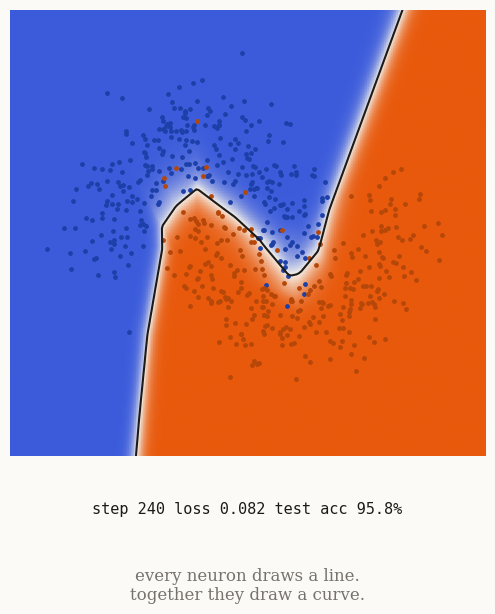

In [17]:
# Redefining the corrected forward function to fix the h1/h2 assignment bug
def forward(x):
  z1=x @ p["W1"]+p["b1"];h1=relu(z1)          #layer 1
  z2=h1 @ p["W2"]+p["b2"];h2=relu(z2)         #layer 2
  out = sigmoid(h2 @ p["W3"]+p["b3"]).ravel()#P orange
  return out, (z1,h1,z2,h2)

acc =lambda:((forward(Xt)[0] > .5) == Yt).mean()

gx,gy=np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.6, 2.1, 150))

grid = np.c_[gx.ravel(), gy.ravel()]

стар = LinearSegmentedColormap.from_list("n", ["#3b5bdb", "#f4f1ea", "#e8590c"])

fig = plt.figure(figsize=(5.4, 7.2), facecolor="#fbfaf7")

ax = fig.add_axes([0.06, 0.3, 0.88, 0.62])

im = ax.imshow(np.full(gx.shape, 0.5), extent=(-2, 3, -1.6, 2.1),
               origin="lower", cmap=стар, vmin=0, vmax=1, aspect="auto")

ax.scatter(*Xt[Yt == 0][:300].T, s=6, c="#1c3fa8")

ax.scatter(*Xt[Yt == 1][:300].T, s=6, c="#b54708")

ax.set_xticks(())
ax.set_yticks(())
ax.set_frame_on(False)

info = fig.text(.5, 0.22, "", ha="center", color="#1d1b18",
                family="monospace", fontsize=11)

fig.text(.5, 0.1, "every neuron draws a line.\ntogether they draw a curve.", ha="center", color="#77726b", family="serif", fontsize=12)

lines = []

def frame(i):
  L = step(i + 1)
  P = forward(grid)[0].reshape(gx.shape)
  im.set_data(P)
  for c in lines:
    c.remove()
  lines[:] = [ax.contour(gx, gy, P, levels=[.5], colors="#1d1b18")]
  info.set_text(f"step {i + 1:>3} loss {L:.3f} test acc {acc():.1%}")
  return [im, info]

anim = animation.FuncAnimation(fig, frame, frames=240,
                               init_func=lambda: [im, info])

anim.save("network.mp4", fps=30, dpi=200)